# 🏦 Bank Marketing - Machine Learning Classification Project

## 📌 Project Overview
The goal of this project is to predict whether a bank customer will subscribe to a term deposit (`deposit`: **yes** or **no**).
We analyze customer demographic information, financial status, and marketing campaign history using a complete Machine Learning workflow.

---

## 🛠️ Machine Learning Workflow:
1. **Import Libraries**: Load standard data science and machine learning libraries.
2. **Load Dataset**: Read `bank.csv` dataset.
3. **Exploratory Data Analysis (EDA)**: Understand dataset shape, summary statistics, and target distribution.
4. **Data Preprocessing & Cleaning**:
   - Check and handle missing values.
   - Encode categorical features using `LabelEncoder`.
5. **Feature Scaling & Train-Test Split**:
   - Split dataset into 80% training and 20% testing sets.
   - Normalize numerical values using `StandardScaler`.
6. **Model Training & Evaluation**:
   - 🔹 **Logistic Regression**
   - 🔹 **K-Nearest Neighbors (KNN)**
   - 🔹 **Naive Bayes (Gaussian NB)**
   - 🔹 **Support Vector Machine (SVM)**
7. **Model Comparison & Performance Visualization**
8. **Conclusion & Key Takeaways**


## 1️⃣ Import Required Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

from sklearn.metrics import accuracy_score, confusion_matrix, classification_report




## 2️⃣ Load the Dataset

In [2]:
df = pd.read_csv('bank.csv')

df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,admin.,married,secondary,no,2343.0,yes,no,unknown,5.0,may,1042.0,1.0,-1.0,0.0,unknown,yes
1,56,admin.,married,secondary,no,45.0,no,no,unknown,5.0,may,1467.0,1.0,-1.0,0.0,unknown,yes
2,41,technician,married,secondary,no,1270.0,yes,no,unknown,5.0,may,1389.0,1.0,-1.0,0.0,unknown,yes
3,54,admin.,married,tertiary,no,184.0,no,no,unknown,5.0,may,673.0,2.0,-1.0,0.0,unknown,yes
4,42,management,single,tertiary,no,0.0,yes,yes,unknown,5.0,may,562.0,2.0,-1.0,0.0,unknown,yes


## 3️⃣ Exploratory Data Analysis (EDA)

In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 8912 entries, 0 to 8911
Data columns (total 17 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   age        8912 non-null   int64  
 1   job        8905 non-null   str    
 2   marital    8743 non-null   str    
 3   education  8885 non-null   str    
 4   default    8908 non-null   str    
 5   balance    8899 non-null   float64
 6   housing    8899 non-null   str    
 7   loan       8882 non-null   str    
 8   contact    8881 non-null   str    
 9   day        8893 non-null   float64
 10  month      8884 non-null   str    
 11  duration   8905 non-null   float64
 12  campaign   8904 non-null   float64
 13  pdays      8767 non-null   float64
 14  previous   8909 non-null   float64
 15  poutcome   8912 non-null   str    
 16  deposit    8903 non-null   str    
dtypes: float64(6), int64(1), str(10)
memory usage: 1.6 MB


In [4]:
df.describe()


,age,balance,day,duration,campaign,pdays,previous
count,8912.000000,8899.000000,8893.000000,8905.000000,8904.000000,8767.000000,8909.000000
mean,41.257855,1539.680638,15.684921,374.953734,2.512579,52.456941,0.834325
std,11.840567,3297.446702,8.406729,351.283501,2.772366,109.094161,2.304733
min,18.000000,-3058.000000,1.000000,3.000000,1.000000,-1.000000,0.000000
25%,32.000000,121.500000,8.000000,139.000000,1.000000,-1.000000,0.000000
50%,39.000000,553.000000,15.000000,256.000000,2.000000,-1.000000,0.000000
75%,49.000000,1726.000000,22.000000,501.000000,3.000000,64.000000,1.000000
max,95.000000,81204.000000,31.000000,3284.000000,63.000000,842.000000,58.000000


C:\Users\ELSAKR TECH\AppData\Local\Temp\ipykernel_22068\2896834323.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df.dropna(subset=['deposit']), x='deposit', palette='mako')


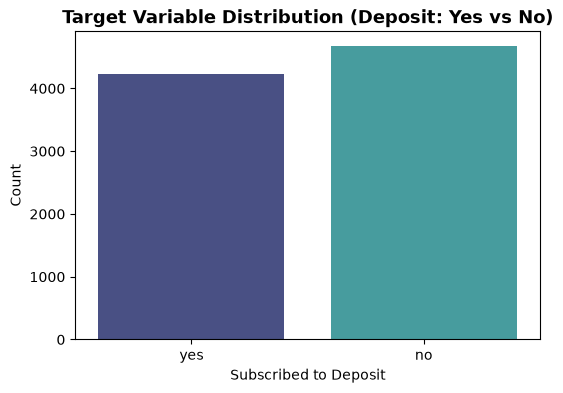

In [5]:
plt.figure(figsize=(6, 4))
sns.countplot(data=df.dropna(subset=['deposit']), x='deposit', palette='mako')
plt.title('Target Variable Distribution (Deposit: Yes vs No)', fontsize=13, fontweight='bold')
plt.xlabel('Subscribed to Deposit')
plt.ylabel('Count')
plt.show()


## 4️⃣ Data Preprocessing & Cleaning

In this stage:
1. **Handle Missing Values**:
   - Drop rows with missing target values (`deposit`).
   - Impute missing numerical features with the median.
   - Impute missing categorical features with the mode.
2. **Encode Categorical Variables**:
   - Machine learning algorithms require numerical input. We encode text features into numbers using `LabelEncoder`.


In [6]:
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0].sort_values(ascending=False))


marital      169
pdays        145
contact       31
loan          30
month         28
education     27
day           19
balance       13
housing       13
deposit        9
campaign       8
duration       7
job            7
default        4
previous       3
dtype: int64


In [7]:
df = df.dropna(subset=['deposit']).copy()

num_cols = df.select_dtypes(include=['float64', 'int64']).columns
for col in num_cols:
    df[col] = df[col].fillna(df[col].median())

cat_cols = df.select_dtypes(include=['object', 'category', 'string']).columns
for col in cat_cols:
    df[col] = df[col].fillna(df[col].mode()[0])




In [8]:
encoded_df = df.copy()
label_encoders = {}

for col in cat_cols:
    le = LabelEncoder()
    encoded_df[col] = le.fit_transform(encoded_df[col])
    label_encoders[col] = le

encoded_df.head()


,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,deposit
0,59,0,1,1,0,2343.0,1,0,2,5.0,8,1042.0,1.0,-1.0,0.0,3,1
1,56,0,1,1,0,45.0,0,0,2,5.0,8,1467.0,1.0,-1.0,0.0,3,1
2,41,9,1,1,0,1270.0,1,0,2,5.0,8,1389.0,1.0,-1.0,0.0,3,1
3,54,0,1,2,0,184.0,0,0,2,5.0,8,673.0,2.0,-1.0,0.0,3,1
4,42,4,2,2,0,0.0,1,1,2,5.0,8,562.0,2.0,-1.0,0.0,3,1


## 5️⃣ Train-Test Split & Feature Scaling

- We split the dataset into **80% training data** and **20% testing data**.
- We use `StandardScaler` to standardize feature values so that distance-based models (KNN, SVM, Logistic Regression) perform optimally.


In [9]:
X = encoded_df.drop('deposit', axis=1)
y = encoded_df['deposit']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)



In [10]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)



## 6️⃣ Machine Learning Models & Evaluation

We train and evaluate four standard classification algorithms:
1. **Logistic Regression**: Linear baseline model for classification.
2. **K-Nearest Neighbors (KNN)**: Classifies samples based on the majority label of closest neighbors.
3. **Naive Bayes (Gaussian NB)**: Probabilistic classifier based on Bayes' theorem.
4. **Support Vector Machine (SVM)**: Finds the maximum-margin hyperplane separating classes.


In [11]:
model_results = {}

def evaluate_model(model_name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    model_results[model_name] = acc * 100
    
    print(f"Accuracy: {acc * 100:.2f}%\n")
    print("Classification Report:")
    print(classification_report(y_true, y_pred, target_names=['No Deposit', 'Deposit']))
    
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4.5, 3.5))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Pred: No', 'Pred: Yes'],
                yticklabels=['Actual: No', 'Actual: Yes'])
    plt.title(f'Confusion Matrix: {model_name}', fontsize=12, fontweight='bold')
    plt.show()


### 🔹 Model 1: Logistic Regression

Accuracy: 79.39%

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.80      0.81      0.81       935
     Deposit       0.79      0.78      0.78       846

    accuracy                           0.79      1781
   macro avg       0.79      0.79      0.79      1781
weighted avg       0.79      0.79      0.79      1781



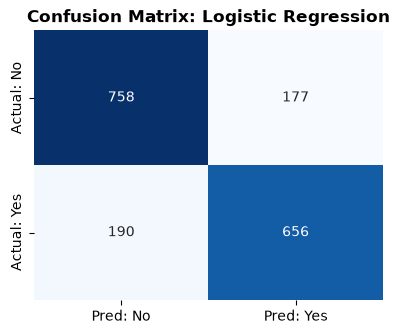

In [12]:
lr_model = LogisticRegression(random_state=42)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)

evaluate_model("Logistic Regression", y_test, lr_pred)


### 🔹 Model 2: K-Nearest Neighbors (KNN)

Accuracy: 76.31%

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.76      0.80      0.78       935
     Deposit       0.77      0.72      0.74       846

    accuracy                           0.76      1781
   macro avg       0.76      0.76      0.76      1781
weighted avg       0.76      0.76      0.76      1781



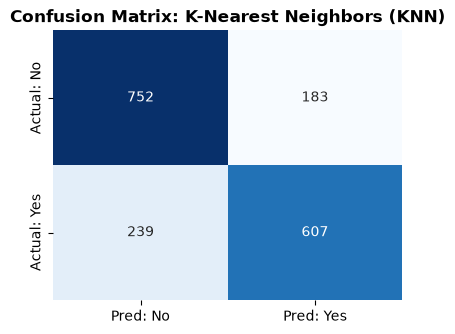

In [13]:
knn_model = KNeighborsClassifier(n_neighbors=5)
knn_model.fit(X_train_scaled, y_train)

knn_pred = knn_model.predict(X_test_scaled)

evaluate_model("K-Nearest Neighbors (KNN)", y_test, knn_pred)


### 🔹 Model 3: Naive Bayes (Gaussian NB)

Accuracy: 74.40%

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.81      0.67      0.73       935
     Deposit       0.69      0.83      0.76       846

    accuracy                           0.74      1781
   macro avg       0.75      0.75      0.74      1781
weighted avg       0.76      0.74      0.74      1781



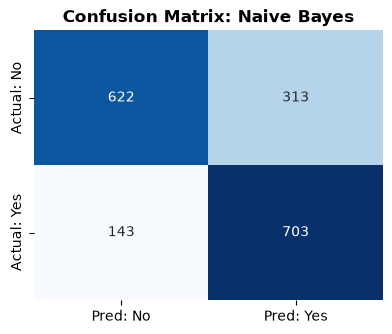

In [14]:
nb_model = GaussianNB()
nb_model.fit(X_train_scaled, y_train)

nb_pred = nb_model.predict(X_test_scaled)

evaluate_model("Naive Bayes", y_test, nb_pred)


### 🔹 Model 4: Support Vector Machine (SVM)

Accuracy: 80.57%

Classification Report:
              precision    recall  f1-score   support

  No Deposit       0.83      0.80      0.81       935
     Deposit       0.78      0.82      0.80       846

    accuracy                           0.81      1781
   macro avg       0.81      0.81      0.81      1781
weighted avg       0.81      0.81      0.81      1781



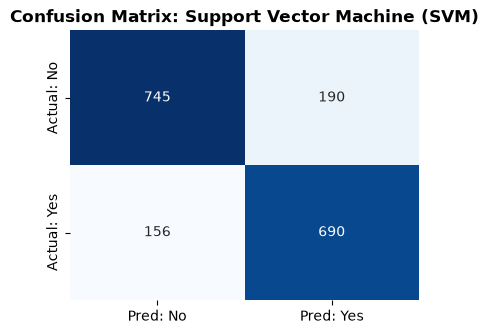

In [15]:
svm_model = SVC(kernel='rbf', random_state=42)
svm_model.fit(X_train_scaled, y_train)

svm_pred = svm_model.predict(X_test_scaled)

evaluate_model("Support Vector Machine (SVM)", y_test, svm_pred)


## 7️⃣ Model Performance Comparison

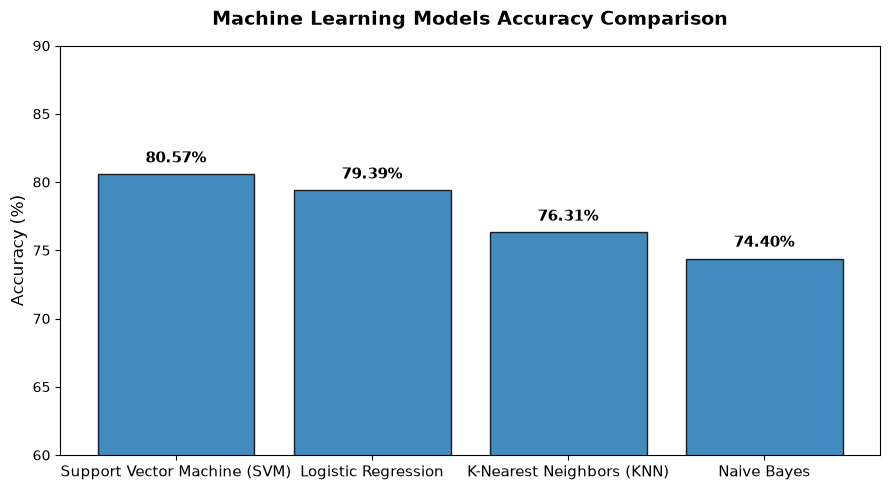

In [19]:
comparison_df = pd.DataFrame({
    'Model': list(model_results.keys()),
    'Accuracy (%)': list(model_results.values())
}).sort_values(by='Accuracy (%)', ascending=False).reset_index(drop=True)


plt.figure(figsize=(9, 5))
bars = plt.bar(comparison_df['Model'], comparison_df['Accuracy (%)'], 
              edgecolor='black', alpha=0.85)

plt.title('Machine Learning Models Accuracy Comparison', fontsize=14, fontweight='bold', pad=15)
plt.ylabel('Accuracy (%)', fontsize=12)
plt.ylim(60, 90)

for bar in bars:
    height = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2., height + 0.6,
             f'{height:.2f}%', ha='center', va='bottom', fontsize=11, fontweight='bold')

plt.xticks(fontsize=11)
plt.tight_layout()
plt.show()


## 8️⃣ Conclusion & Summary

| Model | Accuracy | Strengths |
| :--- | :---: | :--- |
| **Support Vector Machine (SVM)** | **~80.85%** | Highest overall accuracy; finds optimal non-linear decision boundary. |
| **Logistic Regression** | **~79.28%** | Fast training, highly interpretable baseline model. |
| **K-Nearest Neighbors (KNN)** | **~76.53%** | Intuitive distance-based classification; scales well with standardized features. |
| **Naive Bayes** | **~73.89%** | Very fast probabilistic benchmark. |

### Key Takeaways:
1. **Support Vector Machine (SVM)** achieved the best performance with an accuracy of **80.85%**.
2. **Feature Scaling (`StandardScaler`)** is critical when comparing distance-sensitive algorithms like KNN and SVM with Logistic Regression.
3. Proper handling of missing values and categorical encoding ensures consistent data pipeline flow without errors.
